# Predicting hydropower unit commitment in Tokke-Vinje: project report

**Name:** Martin Nordli Almenningen  
**Student id:** 562274  
**Kaggle team name:** [197] sur salamander  
**Group:** 197  
**Course:** TDT4173 Modern Machine Learning in Practice

Figures and computed tables come from the cells below, using the raw data and saved experiment results. Hand-written tables quote the experiment log.

## Contents
1. Summary
2. Task
3. Exploratory data analysis
   - 3.1 Search domain knowledge
   - 3.2 Understand how the data was generated
   - 3.3 Check if the data is intuitive
   - 3.4 Explore individual features
   - 3.5 Explore pairs and groups of features
   - 3.6 Clean up features
4. Validation
5. Feature engineering
6. All models and algorithms tried
7. Final models and hyperparameters
8. Model interpretation
9. Error analysis
10. Robustness
11. Reproducibility
12. Limitations

In [1]:
import sys, json, re, warnings
sys.path.insert(0, "src"); sys.dont_write_bytecode = True; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from common import load_cases, years, auc, RES, INFLOW, MINFLOW, MINVOL
from lp_surrogate import UNITS
from features import TOPO, UP, DOWN, PMAX, PLANTS, group

BLUE, ORANGE, AQUA, YELLOW, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8, "lines.linewidth": 2})
def heat(ax, M, xl, yl, title, vmin=None, vmax=None, fmt="{:.3f}", cmap="Blues", size=7):
    im = ax.imshow(M, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax); ax.grid(False); ax.set_xticks(range(len(xl)), xl); ax.set_yticks(range(len(yl)), yl); ax.set_title(title)
    lo, hi = np.nanmin(M) if vmin is None else vmin, np.nanmax(M) if vmax is None else vmax
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=size, color="white" if (M[i, j] - lo) / (hi - lo + 1e-12) > .6 else INK)
    return im

pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 220)
c = load_cases(); Y = c["Y"]; P = c["price"]; yr = years(c); N_TR = 2922; ytr = yr[:N_TR]; YRS = list(range(2015, 2023)); starts = pd.to_datetime(c["start"])
rows = {}
for l in open("experiments.jsonl"):
    d = json.loads(l); rows[d["name"]] = d
XT, NT = np.load("artifacts/oof/XR_ls.npy").astype(np.float64), np.load("artifacts/oof/N6_min.npy").astype(np.float64); B = .7 * XT + .3 * NT
Z = np.load("artifacts/lp/lp4_b10.npz"); LPF = Z["pfrac"].astype(np.float64); LPU = Z["u"].astype(np.float64)
XF, NF = np.load("artifacts/fwd/XR_ls_f.npy").astype(np.float64), np.load("artifacts/fwd/N6f_min.npy").astype(np.float64)
print("LOYO blend", round(auc(Y, B), 5), "| forward blend", round(auc(Y[np.isfinite(XF).all((1, 2))], (.7 * XF + .3 * NF)[np.isfinite(XF).all((1, 2))]), 5))

LOYO blend 0.994 | forward blend 0.99379


## 1. Summary

I wrote a linear program (LP) of the whole watercourse, solved it three times per case with HiGHS, and gave the solutions to the models as features. The LP reads only the case inputs and the topology file and has no trained parameters. The models learn the gap between the LP and SHOP.

| Submission | Model | LOYO AUC (2015-22) | Forward AUC (2019-22) | Public LB |
|---|---|---|---|---|
| **Short notebook 1** | XGBoost + ST-Net, logit blend 0.7/0.3 | 0.99400 | 0.99379 | **0.99638** |
| **Short notebook 2** | Same, ST-Net without absolute price columns | 0.99399 | 0.99379 | 0.99635 |
| B2, earlier blend | 3 GBDT + 2 ST-Net, nested weights | 0.99377 | - | 0.99626 |
| E021a, best without LP | LightGBM + ST-Net, nested weights | 0.98584 | - | 0.98906 |

Selection used LOYO and forward validation. The public leaderboard was only a check. The two submissions are nearly identical (Spearman 0.99889); notebook 2 hedges one specific risk (Section 10.2).

Main limitations (Section 12): the LP was designed using labels from all training years, and behaviour at negative prices cannot be verified.

## 2. Task

SHOP, SINTEF's scheduling software, solved a one-week schedule for Tokke-Vinje (17 reservoirs, 9 plants, 14 units, 1000 MW) for each day from 2015-01-01 to 2024-12-25. The task is to predict on/off for each unit and each of the 168 hours in a case. The metric is micro-averaged ROC AUC.

- **Train:** 2922 cases, 2015-2022.
- **Test:** 725 cases, 2023-01-01 to 2024-12-25. The split is in time, so this is extrapolation.
- **Inputs:** hourly prices and inflows, daily volumes and water values, minimum flow and volume constraints, topology.

Grading uses the private leaderboard, so I optimised for new years, not the public score.

## 3. Exploratory data analysis
### 3.1 Search domain knowledge

Sources: the task description, the dataset documentation, the SHOP documentation and the topology files.

- **Water value:** the estimated future worth of a reservoir's marginal water, in EUR/MWh. A unit should roughly run when the price exceeds the value of the water it uses.
- **Cascades:** released water reaches a lower reservoir, where it still has value. The cost of running depends on the watercourse.
- **Efficiency and head:** power is a concave function of flow and depends on head and on tunnel and penstock losses.
- **Non-convexity:** start costs, minimum power and on/off status make the true problem a mixed-integer program. Identical units create symmetry, which solvers usually break with a fixed order.
- **Environmental constraints:** minimum flows and volumes can force production or bypass at any price.
- **Floods:** water about to spill is nearly free, so units may run at very low prices.

### 3.2 Understand how the data was generated

The labels are the output of an optimiser (SHOP v17.17.0) on a fixed model, not noisy measurements. Two consequences:

1. Remaining error is something not yet modelled, which motivates rebuilding the optimisation problem.
2. Only what SHOP received is a legitimate input: 168 hours of price, inflow and constraints, start volumes at day $d$, and water values at $d+7$. The feature code cannot reach later volumes or intermediate water values.

Cases roll daily, so neighbours share 6 of 7 days.

In [2]:
agree = {f"{l} day(s) later": float((Y[l:, :, :168 - 24 * l] == Y[:-l, :, 24 * l:]).mean()) for l in (1, 2, 3, 6)}
uc = pd.read_csv("data/kernel/Unit_commitment_decisions.csv", usecols=["starttime", "total_calculation_time"], parse_dates=["starttime"])
print("Share of identical decisions for the same clock hour when solved again:", {k: round(v, 3) for k, v in agree.items()})
print("SHOP solve time per case, seconds:", uc.total_calculation_time.describe()[["min", "50%", "max"]].round(1).to_dict())
print("Median per year:", uc.groupby(uc.starttime.dt.year).total_calculation_time.median().round(1).to_dict())
print("Label shape", Y.shape, "| share on", round(Y.mean(), 4), "| case on-share constant through week:", round(((Y.sum(2) == 0) | (Y.sum(2) == 168)).mean(), 3))
i = UNITS.index
print("\nFixed order among identical units, share of hours where the first is on whenever the second is:")
for a, b in [("Vinje_G1", "Vinje_G2"), ("Vinje_G2", "Vinje_G3"), ("Tokke_G1", "Tokke_G3"), ("Tokke_G3", "Tokke_G2"), ("Tokke_G3", "Tokke_G4"), ("Tokke_G4", "Tokke_G2")]:
    print(f"  {a} >= {b}: {(Y[:, i(a)] >= Y[:, i(b)]).mean():.4f}")

Share of identical decisions for the same clock hour when solved again: {'1 day(s) later': 0.878, '2 day(s) later': 0.812, '3 day(s) later': 0.779, '6 day(s) later': 0.742}
SHOP solve time per case, seconds: {'min': 22.4, '50%': 51.7, 'max': 4525.7}
Median per year: {2015: 50.5, 2016: 53.1, 2017: 61.6, 2018: 60.3, 2019: 60.5, 2020: 51.8, 2021: 45.3, 2022: 38.2}
Label shape (2922, 14, 168) | share on 0.5164 | case on-share constant through week: 0.588

Fixed order among identical units, share of hours where the first is on whenever the second is:
  Vinje_G1 >= Vinje_G2: 0.9993
  Vinje_G2 >= Vinje_G3: 0.9998
  Tokke_G1 >= Tokke_G3: 0.9995
  Tokke_G3 >= Tokke_G2: 0.9994
  Tokke_G3 >= Tokke_G4: 0.9971
  Tokke_G4 >= Tokke_G2: 0.9813


- Only 88 % of decisions for the same clock hour survive a re-solve one day later, and 74 % six days later. Smoothing predictions across neighbouring cases made every year worse (Section 6.1).
- 59 % of unit-weeks are constant (all on or all off), so the weekly level matters.
- Identical units follow a near-deterministic start order. The LP uses all six pairs. ST-Net's output layer uses the first five, since the last holds in only 98.1 % of hours.

### 3.3 Check if the data is intuitive

Do units run when the price exceeds the water value? Does on-share follow the market?

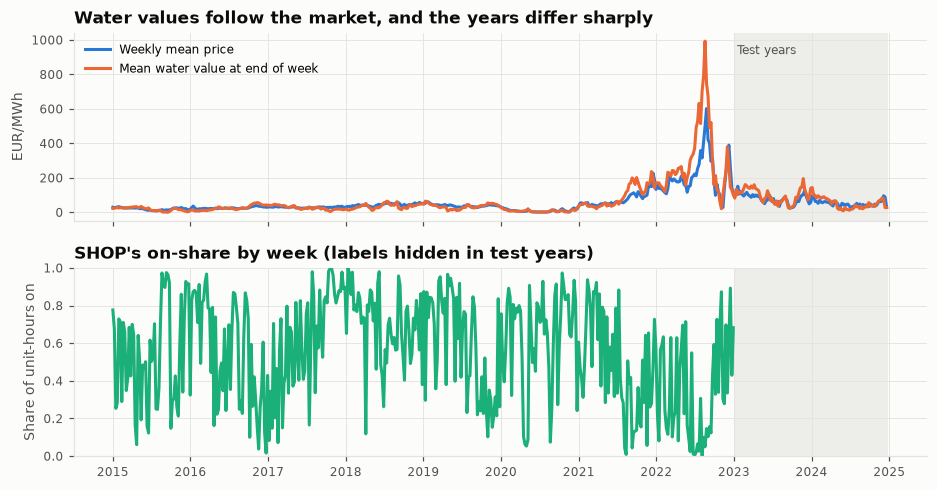

In [3]:
ri = {r: k for k, r in enumerate(RES)}; wk = np.arange(0, len(P), 7); dates = starts[wk]; wv = c["wv_end"]
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw=dict(hspace=.25))
ax[0].plot(dates, P.mean(1)[wk], color=BLUE, label="Weekly mean price"); ax[0].plot(dates, wv.mean(1)[wk], color=ORANGE, label="Mean water value at end of week")
ax[0].axvspan(starts[N_TR], starts[-1], color=GRID, alpha=.6, lw=0); ax[0].text(starts[N_TR + 15], ax[0].get_ylim()[1] * .88, "Test years", fontsize=8, color=MUTED); ax[0].set_ylabel("EUR/MWh"); ax[0].set_title("Water values follow the market, and the years differ sharply"); ax[0].legend(loc="upper left")
ax[1].plot(starts[:N_TR][wk[wk < N_TR]], Y[wk[wk < N_TR]].mean((1, 2)), color=AQUA); ax[1].axvspan(starts[N_TR], starts[-1], color=GRID, alpha=.6, lw=0); ax[1].set_ylabel("Share of unit-hours on"); ax[1].set_title("SHOP's on-share by week (labels hidden in test years)"); ax[1].set_ylim(0, 1); plt.show()

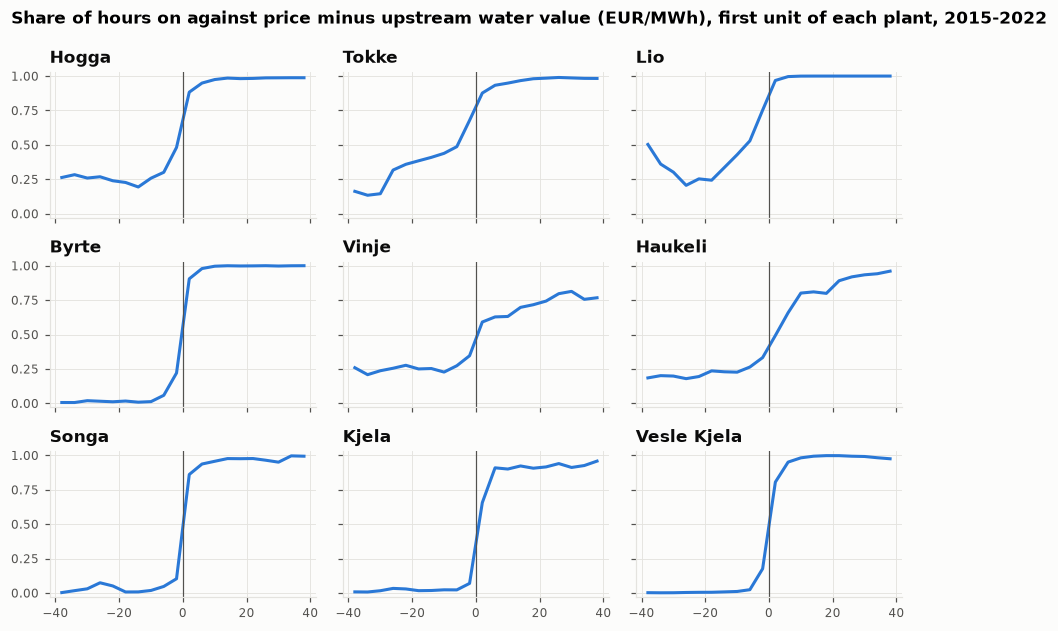

,plant,weeks,coef_wv_up,coef_wv_down,intercept,R2
0,Hogga,1080,0.86,0.00,-2.82,0.87
1,Tokke,1141,0.58,0.26,0.39,0.81
2,Lio,671,0.49,0.12,11.13,0.92
3,Byrte,584,1.04,-0.03,-0.32,0.98
4,Vinje,1074,0.53,0.50,5.90,0.92
5,Haukeli,454,0.57,0.13,17.37,0.79
6,Songa,792,0.72,0.12,8.11,0.94
7,Kjela,905,0.71,0.15,10.98,0.96
8,Vesle Kjela,575,0.86,0.07,3.97,0.95


In [4]:
fig, axs = plt.subplots(3, 3, figsize=(10, 6.2), sharex=True, sharey=True, gridspec_kw=dict(hspace=.3, wspace=.1)); bins = np.arange(-40, 41, 4); rowsT = []
for ax, pl in zip(axs.ravel(), PLANTS):
    u0 = [k for k, u in enumerate(UNITS) if TOPO.gen_plant[u] == pl][0]; w = wv[:N_TR, ri[UP[u0]]]; d = (P[:N_TR] - w[:, None]).ravel(); y = Y[:, u0].ravel(); b = np.digitize(d, bins); xs, ys = [], []
    for k in range(1, len(bins)):
        if (b == k).sum() > 200: xs.append((bins[k - 1] + bins[k]) / 2); ys.append(y[b == k].mean())
    ax.plot(xs, ys, color=BLUE); ax.axvline(0, color=MUTED, lw=.8); ax.set_title(pl); ax.set_ylim(-.03, 1.03)
    on = Y[:, u0].astype(bool); mix = (on.sum(1) >= 12) & (on.sum(1) <= 156); th = np.array([(np.median(P[k][on[k]]) + np.median(P[k][~on[k]])) / 2 for k in np.where(mix)[0]])
    wu = wv[:N_TR, ri[UP[u0]]][mix]; wd = wv[:N_TR, ri[DOWN[u0]]][mix] if DOWN[u0] else np.zeros(mix.sum()); A = np.c_[wu, wd, np.ones(len(wu))]; co = np.linalg.lstsq(A, th, rcond=None)[0]
    rowsT.append(dict(plant=pl, weeks=int(mix.sum()), coef_wv_up=co[0], coef_wv_down=co[1], intercept=co[2], R2=1 - ((th - A @ co) ** 2).sum() / ((th - th.mean()) ** 2).sum()))
fig.suptitle("Share of hours on against price minus upstream water value (EUR/MWh), first unit of each plant, 2015-2022", fontsize=11, fontweight="bold", x=.09, ha="left", y=.97); plt.show()
display(pd.DataFrame(rowsT).round(2))

Mostly yes, with exceptions:

- Weekly price and mean water value correlate at 0.93, so a high price alone does not mean a unit should run.
- On-share rises across zero margin. Byrte, Songa, Kjela and Vesle Kjela are close to clean steps. Hogga, Tokke, Lio, Vinje and Haukeli still run 15-50 % of the time at strongly negative margins, possibly from minimum flow or spill.
- The table regresses a rough per-week price threshold (midway between median on and off prices) on water values. The upstream coefficient is largest for every plant, but Vinje (0.53, 0.50) and Tokke (0.58, 0.26) also weight the downstream value. The estimator is crude, so this is only a hint.

My first reading was wrong: converting a reservoir's water value with its own energy factor, locally or summed down the cascade, gave an LP AUC of 0.606 and 0.743. Telescoping values gave 0.932 (Section 5.1). Only testing against labels revealed this.

### 3.4 Explore individual features

,min,median,mean,max,% negative hours
"Price, EUR/MWh",,,,,
2015,1.03,21.96,19.82,69.68,0.00
2016,6.01,23.60,25.15,95.06,0.00
2017,2.97,28.94,28.83,114.70,0.00
2018,1.92,43.63,43.25,105.02,0.00
2019,5.86,38.81,39.26,109.45,0.00
2020,-1.73,6.95,9.29,99.92,0.06
2021,-1.97,59.34,75.11,600.16,0.06
2022,0.04,181.13,211.28,844.00,0.00
2023,-61.84,80.46,79.44,261.85,1.99


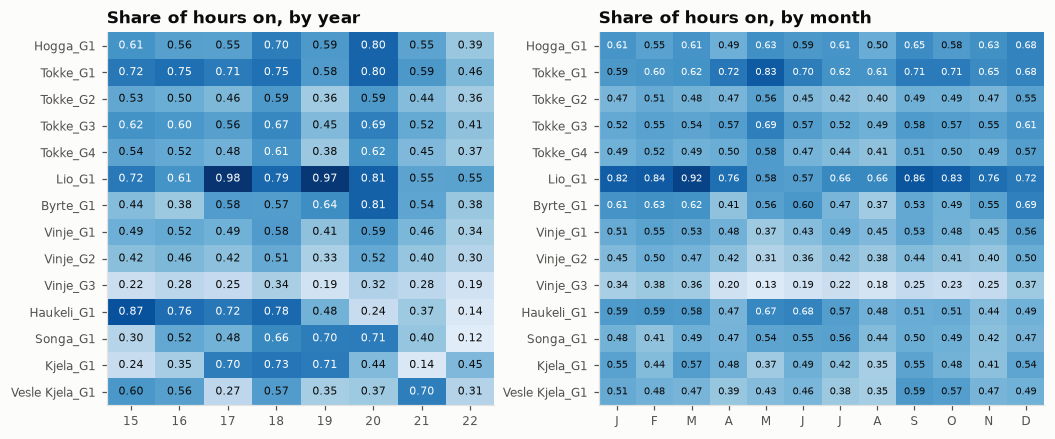

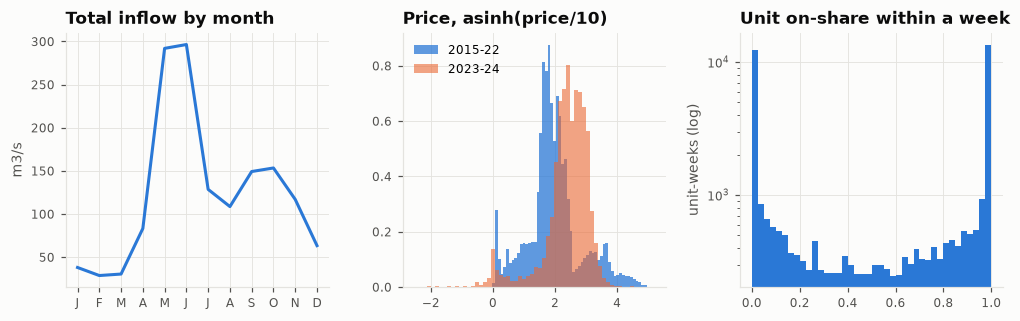

Hours with negative prices inside cases, train: 0.014 % | test: 2.18 %
Switches per unit-week: {'Hogga_G1': 1.7, 'Tokke_G1': 3.0, 'Tokke_G2': 2.0, 'Tokke_G3': 2.5, 'Tokke_G4': 2.1, 'Lio_G1': 1.2, 'Byrte_G1': 1.0, 'Vinje_G1': 3.0, 'Vinje_G2': 3.3, 'Vinje_G3': 3.6, 'Haukeli_G1': 0.5, 'Songa_G1': 2.0, 'Kjela_G1': 2.3, 'Vesle Kjela_G1': 0.7}


In [5]:
h = pd.read_csv("data/kernel/Historical_day_ahead_price_2015_2025.csv", parse_dates=["date"]).set_index("date").iloc[:, 0]; h.index = pd.to_datetime(h.index, utc=True); h = h["2015":"2024-12-31"]; g = h.groupby(h.index.year)
display(pd.DataFrame({"min": g.min(), "median": g.median(), "mean": g.mean(), "max": g.max(), "% negative hours": g.apply(lambda s: (s < 0).mean() * 100)}).round(2).rename_axis("Price, EUR/MWh"))
months = starts[:N_TR].month.values; ml = "J F M A M J J A S O N D".split()
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw=dict(wspace=.25, width_ratios=[1, 1.15]))
heat(ax[0], np.array([[Y[ytr == y, g_].mean() for y in YRS] for g_ in range(14)]), [str(y)[2:] for y in YRS], UNITS, "Share of hours on, by year", 0, 1, "{:.2f}")
heat(ax[1], np.array([[Y[months == m, g_].mean() for m in range(1, 13)] for g_ in range(14)]), ml, UNITS, "Share of hours on, by month", 0, 1, "{:.2f}", size=6.5); plt.show()
hh = (P[:N_TR] - np.median(P[:N_TR], 1, keepdims=True)); q = pd.read_csv("data/kernel/Historical_inflow_1958_2025.csv", parse_dates=["date"]).set_index("date"); q.index = pd.to_datetime(q.index, utc=True); q15 = q["2015":"2022"]
fig, ax = plt.subplots(1, 3, figsize=(11, 3), gridspec_kw=dict(wspace=.28))
ax[0].plot(range(1, 13), q15.sum(axis=1).groupby(q15.index.month).mean(), color=BLUE); ax[0].set_xticks(range(1, 13), ml); ax[0].set_title("Total inflow by month"); ax[0].set_ylabel("m3/s")
ax[1].hist(np.arcsinh(h.loc["2015":"2022"] / 10), bins=60, color=BLUE, density=True, label="2015-22", alpha=.75); ax[1].hist(np.arcsinh(h.loc["2023":] / 10), bins=60, color=ORANGE, density=True, label="2023-24", alpha=.6); ax[1].set_title("Price, asinh(price/10)"); ax[1].legend()
ll = Y.mean(2).ravel(); ax[2].hist(ll, bins=40, color=BLUE); ax[2].set_title("Unit on-share within a week"); ax[2].set_yscale("log"); ax[2].set_ylabel("unit-weeks (log)"); plt.show()
print("Hours with negative prices inside cases, train:", round(float((P[:N_TR] < 0).mean()) * 100, 3), "% | test:", round(float((P[N_TR:] < 0).mean()) * 100, 2), "%")
print("Switches per unit-week:", {u: round(float(v), 1) for u, v in zip(UNITS, np.abs(np.diff(Y, axis=2)).sum(2).mean(0))})

- **Regimes:** median price ranged from 7 EUR/MWh (2020) to 181 (2022), while on-share fell from 0.60 to 0.34. Price level alone does not explain the labels.
- **Heavy tails:** prices reach 898 and -62 EUR/MWh. `asinh` handles both.
- **Test shift:** negative prices are 2.2 % of test hours and 0.014 % of train hours. Otherwise test prices stay near the training range (maximum 898 against 844).
- **Season:** inflow peaks in May and June, with a smaller autumn peak. The effect depends on the plant: Tokke G1 peaks in May (0.83), while Lio and Vinje G3 dip.
- **Base rates** differ between units (Vinje G3 26 %, Lio 75 %) and years (Kjela 14 % in 2021, 73 % in 2018).
- **Weekly on-share** is bimodal, with spikes at 0 and 1.

### 3.5 Explore pairs and groups of features

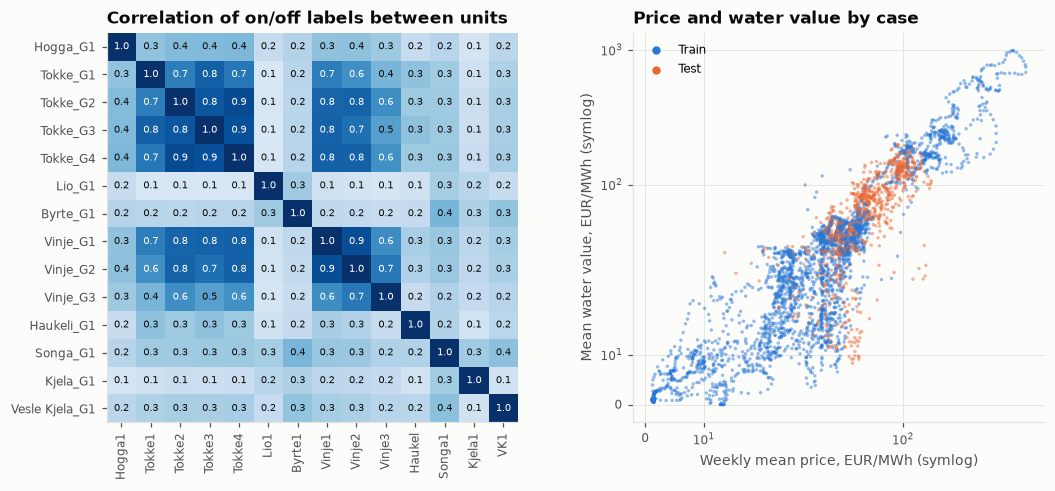

Correlation between weekly mean price and mean water value: 0.93
Correlation between reservoirs' water values, min and median: 0.76 0.88
Share of hours with a non-zero minimum flow: {'b_Kjelavatn': 1.0, 'b_Hyljelihyl': 1.0, 'b_Vinjevatn': 1.0, 'b_Byrtevatn': 0.34, 'b_Bandak': 1.0, 'r_Vest_Vassdraget': 1.0}
Share of hours with a non-zero minimum volume: {'Totak': 0.34, 'Byrtevatn': 0.13, 'Staavatn': 0.26}
Reservoir fill, mean over days: {'Kjelavatn': 0.5, 'Staavatn': 0.57, 'Langesae': 0.7, 'Foersvatn': 0.58, 'Venemo': 0.71, 'Botnedalsvatn': 0.6, 'Bitdalsvatn': 0.71, 'Vaamarvatn': 0.54, 'Langeidvatn': 0.71, 'Totak': 0.65, 'Songavatn': 0.66, 'Vinjevatn': 0.68, 'Bandak': 0.76, 'Bordalsvatn': 0.72, 'Byrtevatn': 0.72, 'Hyljelihyl': 0.5, 'Vatjern': 0.5}


In [6]:
wvc = np.corrcoef(wv.T); labc = np.corrcoef(Y.transpose(1, 0, 2).reshape(14, -1))
vmat = np.array(pd.read_csv("data/kernel/Historical_volume_2015_2024.csv", index_col=0)[RES]); mx = np.array([float(TOPO.res[r]["max_vol"]) for r in RES])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw=dict(wspace=.28))
heat(ax[0], labc, [u.replace("_G", "") .replace("Vesle Kjela", "VK")[:6] for u in UNITS], UNITS, "Correlation of on/off labels between units", -.1, 1, "{:.1f}", size=6.5); ax[0].tick_params(axis="x", rotation=90)
ax[1].scatter(P.mean(1), wv.mean(1), s=5, c=np.where(np.arange(len(P)) < N_TR, BLUE, ORANGE), alpha=.5, linewidths=0); ax[1].set_xscale("symlog", linthresh=30); ax[1].set_yscale("symlog", linthresh=30); ax[1].set_xlabel("Weekly mean price, EUR/MWh (symlog)"); ax[1].set_ylabel("Mean water value, EUR/MWh (symlog)"); ax[1].set_title("Price and water value by case")
for lab, col in (("Train", BLUE), ("Test", ORANGE)): ax[1].scatter([], [], s=20, c=col, label=lab)
ax[1].legend(); plt.show()
print("Correlation between weekly mean price and mean water value:", round(float(np.corrcoef(P.mean(1), wv.mean(1))[0, 1]), 2)); print("Correlation between reservoirs' water values, min and median:", round(float(wvc.min()), 2), round(float(np.median(wvc)), 2))
print("Share of hours with a non-zero minimum flow:", {k: round(float(v), 2) for k, v in zip(MINFLOW, (c["minflow"] > 0).mean((0, 1)))}); print("Share of hours with a non-zero minimum volume:", {k: round(float(v), 2) for k, v in zip(MINVOL, (c["minvol"] > 0).mean((0, 1)))})
print("Reservoir fill, mean over days:", {k: round(float(v), 2) for k, v in zip(RES, (vmat / mx).mean(0))})

- Units in a plant correlate strongly, as do the hydraulically linked Tokke and Vinje (0.4-0.8). Other pairs are low (0.1-0.4).
- Water values across reservoirs correlate at 0.76 or more (median 0.88), so ratios and differences carry the signal.
- Constraints mostly follow the calendar and add little as columns (E004, R3). Their effect comes through the LP's water balance.
- Test cases mostly lie in the same price and water value band as train cases.

**Adversarial validation.** A classifier separates test hours from train hours, using alternating 60-day blocks to keep overlapping cases together. Calendar and unit columns are excluded, since they let it memorise which dates are test.

In [7]:
dr = json.load(open("artifacts/drift.json")); display(pd.DataFrame(dr).T.assign(auc=lambda d: d.auc.astype(float).round(3)).rename_axis("Feature set").rename(columns={"n": "columns", "auc": "adversarial AUC", "top": "most used columns"}))

,columns,adversarial AUC,most used columns
Feature set,,,
with_absolute,62,0.953,"[week_price_iqr_asinh, week_price_mean_asinh, econ_frac_wv, lp_margin_ratio, ls_week_band, price_asinh]"
no_absolute,56,0.921,"[lp_switches, price_over_wv_up, lp_bypass_up_t, start_hours_wv, ls_week_band, lp_dist_switch]"
lp_only,42,0.869,"[lp_switches, lp_margin_ratio, lp_sys_t, ls_week_band, ls_week_cheap, lp_margin_roll5]"
absolute_only,6,0.922,"[week_price_iqr_asinh, week_price_mean_asinh, price_asinh, lp_be_asinh, wv_down_asinh, wv_up_asinh]"


No set comes close to 0.5, so all models must extrapolate. Dropping absolute price columns lowers the AUC from 0.953 to 0.921, and LP columns alone give 0.869. A first version with calendar columns gave impossible results (a superset scoring below its subset), which exposed the memorisation. Drift decided nothing by itself: the net kept the absolute columns because validation favoured them.

### 3.6 Clean up features

- **Gaps and duplicates:** none in the case windows, asserted for all 3647 cases. Labels are strictly 0 or 1. No imputation.
- **Constant columns:** volumes for `Hyljelihyl` and `Vatjern` are constant (no records, assumed 50 % full). `fill_up` is therefore empty for Haukeli and `fill_down` for Kjela. Kept, since trees can ignore them and the LP models the full water balance.
- **Time:** files are in UTC. `hour_local` and `weekday_local` use Oslo time, since the market does.
- **Scaling:** absolute levels use `asinh(x/10)`. Case-relative columns divide by the case's interquartile range. Net inputs are standardised on the training fold and clipped to ±6.
- **Removal:** by the gate (Section 5.3).

## 4. Validation

Folds, metric and lock are protected by SHA256 hashes checked at run time.

- **LOYO:** 8 folds, 2015-2022, with a 7-day purge on both sides to remove training cases sharing an hour with validation.
- **Forward:** train strictly before 2019, 2020, 2021 and 2022. Closest to the real split.
- **Gate:** LOYO gain above seed noise (0.0001, measured with 5 XGBoost seeds), at least 6 of 8 years up, forward loss within noise, committed code. Hypotheses were logged before each run.
- **Label control:** shuffled whole-case labels give 0.589, the level of base rates alone. No leakage visible.

Earlier blend weights were nested. The final weight was not (Section 7).

## 5. Feature engineering
### 5.1 Feature extraction: the LP surrogate

For each case I solve:

$$\max \sum_t \lambda_t \sum_{g} P_{g,t} \; + \; \sum_r v_r V_{r,168} \; - \; \text{flow costs} \; - \; \text{switching costs}$$

subject to water balance for all 17 reservoirs, volume bounds, minimum flow, minimum volume and relaxed commitment $u_{g,t}\in[0,1]$. Power is concave piecewise-linear in flow, built per unit from the YAML turbine and generator curves at the head implied by the start volume, including penstock and shared-tunnel losses. Head is fixed within the week. No labels or fitted parameters are used.

**Telescoping water values** are the key decision. Water ending the week in reservoir $r$ is worth:

$$\text{value}(r) = w_r \cdot \text{conv}(\text{first plant below } r) + \text{value}(\text{reservoir below that plant})$$

so a plant's margin nets out to about price minus upstream water value.

| LP version | Change | AUC of $u$, no training | AUC of power fraction |
|---|---|---|---|
| `lp_local` | Local value per reservoir | 0.6062 | 0.6495 |
| `lp_global` | Global value down the cascade | 0.7431 | 0.7581 |
| `lp_tele` | Telescoping | 0.9323 | 0.9470 |
| `lp_v2`, `lp_v3` | Per-unit curves, head loss, priority order | 0.9442, 0.9558 | 0.9561, 0.9688 |
| **`lp4_b10`, final** | Corrected Tokke order, river costs, bypass cost 10 | **0.9576** | **0.9705** |
| `lp4_b100`, `lp4_b1000` | Bypass cost sweep | 0.9527, 0.9517 | 0.9656, 0.9646 |
| `milp_v2`, `mp4_b10` | Integer schedule on v2, v4 | 0.9296, 0.9441 | 0.9445, 0.9606 |

Scores cover all 2922 training cases. The relaxed LP beats the integer MILP, and MILP features did not help the trees (L3). The final features use three solves per case: water values x1.0, x0.9 and x1.1.

In [8]:
interp = json.load(open("artifacts/interp_final.json")); G = interp["groups"]
display(pd.DataFrame([dict(group=k, columns=len(v), examples=", ".join(v[:7]) + (" ..." if len(v) > 7 else "")) for k, v in G.items()]).set_index("group"))
print("Dropped from trees (ST-Net in notebook 1 keeps them):", open("artifacts/scale_cols.txt").read().strip())

,columns,examples
group,,
market,10,"price_asinh, price_z, price_rank_week, price_rank_day, price_diff_prev, price_diff_next, price_dev_7h ..."
calendar,5,"hour_local, weekday_local, doy_sin, doy_cos, horizon_hour"
unit,5,"unit_id, plant_id, unit_index, p_max, start_per_mw"
lp_schedule,36,"lp_u, lp_p, lp_margin, lp_margin_ratio, lp_be_asinh, lp_be_gap_wv, lp_u_prev1 ..."
lp_sensitivity,7,"ls_u_cheap, ls_u_dear, ls_band, ls_week_cheap, ls_week_dear, ls_week_band, ls_mean"
water_state,9,"wv_up_asinh, wv_down_asinh, fill_up, fill_down, inflow_up_asinh, margin_wv_up, price_over_wv_up ..."


Dropped from trees (ST-Net in notebook 1 keeps them): price_asinh,week_price_mean_asinh,week_price_iqr_asinh,wv_up_asinh,wv_down_asinh,lp_be_asinh


### 5.2 Features built on the LP

- **Schedule (`lp_*`, 36):** commitment and power, neighbours in time, rolling means, marginal cost from shadow prices (`lp_margin`, `lp_margin_ratio`), hours to the nearest switch, output per plant, neighbouring plants and system, reservoir trajectories, bypass flow.
- **Sensitivity (`ls_*`, 7):** the LP at water values x0.9 and x1.1. A decision that flips is a near-tie, where the LP most likely disagrees with SHOP. `ls_mean` averages the three schedules.
- **Market and calendar (15):** ranks within week and day, deviations from rolling means, local time.
- **Unit and water state (14):** identity, capacity, start cost per MW, price against water value, fill and inflow.

Phase 1 used hand-built features for break-even prices, hydraulic state, neighbouring plants and system state (Section 6.1). The LP replaced them.

### 5.3 Feature selection

Each change went through the gate, with XGBoost or ST-Net at 3 seeds unless noted.

In [9]:
def row(n, ref=None):
    r = rows[n]; return r["oof_auc"], (r["oof_auc"] - rows[ref]["oof_auc"]) if ref else np.nan
T = [("Add `ls_*` (trees)", "XR_ls", "XR_min", "XR_ls_f", "XR_min_f", "Accepted. 66 features, 7/8 years"),
     ("Add `ls_*`, keep `mf_*`, `lps_*` (trees)", "XR_sens2", "XR_ref", "XR_sens_f2", "XR_ref_f", "Passes, but no better than the row above with 13 fewer features"),
     ("Drop `mf_*` constraint columns (trees)", "XR_nomf", "XR_ref", "XR_nomf_f", "XR_ref_f", "Inside noise, dropped for simplicity"),
     ("Drop `lps_*` plant shares (trees)", "XR_nolps", "XR_ref", "XR_nolps_f", "XR_ref_f", "Inside noise, dropped for simplicity"),
     ("Drop both (trees)", "XR_min", "XR_ref", "XR_min_f", "XR_ref_f", "No change, 59 vs 72 features"),
     ("Keep absolute price columns (trees)", "XR_scale", "XR_ref", "XR_scale_f", "XR_ref_f", "Inside noise, so left out of the trees"),
     ("Keep absolute price columns (net)", "N4_v4_scale", "N3_v4_mf", "N4f_e24_scale", "N3f3_e24", "Clear gain, kept in the net in notebook 1"),
     ("`base,lp,ls` only (net)", "N6_min", "N4_v4_scale", "N6f_min", "N4f_e24_scale", "Accepted. 7/8 years, 4/4 forward"),
     ("Add `ls_*`, keep `mf_*`, `lps_*` (net)", "N5_ls", "N4_v4_scale", "N5f_ls", "N4f_e24_scale", "Fails, 4/8 years"),
     ("Drop absolute price columns again (net, hedge)", "N7_noabs", "N6_min", "N7f_noabs", "N6f_min", "Fails the gate by design. Used as the hedge in notebook 2")]
display(pd.DataFrame([{"Change": a, "LOYO": rows[n]["oof_auc"], "d LOYO": rows[n]["oof_auc"] - rows[rf]["oof_auc"], "d forward": rows[nf]["oof_auc"] - rows[rff]["oof_auc"], "columns": rows[n].get("n_features"), "Decision": note} for a, n, rf, nf, rff, note in T]).round(5).set_index("Change"))

,LOYO,d LOYO,d forward,columns,Decision
Change,,,,,
Add `ls_*` (trees),0.99349,0.00023,0.00037,66,"Accepted. 66 features, 7/8 years"
"Add `ls_*`, keep `mf_*`, `lps_*` (trees)",0.99349,0.00023,0.00035,79,"Passes, but no better than the row above with 13 fewer features"
Drop `mf_*` constraint columns (trees),0.99325,-0.00001,-0.00007,68,"Inside noise, dropped for simplicity"
Drop `lps_*` plant shares (trees),0.99321,-0.00005,-0.00006,63,"Inside noise, dropped for simplicity"
Drop both (trees),0.99326,0.00000,0.00000,59,"No change, 59 vs 72 features"
Keep absolute price columns (trees),0.99328,0.00003,0.00004,78,"Inside noise, so left out of the trees"
Keep absolute price columns (net),0.99270,0.00023,0.00070,76,"Clear gain, kept in the net in notebook 1"
"`base,lp,ls` only (net)",0.99334,0.00064,0.00083,70,"Accepted. 7/8 years, 4/4 forward"
"Add `ls_*`, keep `mf_*`, `lps_*` (net)",0.99276,0.00006,0.00017,83,"Fails, 4/8 years"


I expected removing absolute price levels to help everywhere, since they drift most. They add nothing to the trees, but raise the net's forward AUC by 0.0007, mostly from 2020, so the net kept them. Notebook 2 hedges this decision.

## 6. All models and algorithms tried

### 6.1 Phase 1: without the LP

LOYO over 8 years unless marked *tuning* (2018, 2020, 2022 only). Gate noise in this phase was 0.00084.

| Id | Model or idea | AUC | Outcome |
|---|---|---|---|
| E000 | LightGBM, base features | 0.95415 | Reference. Weakest year 2020 (0.92178) |
| E006 | Logistic regression (25 % of rows) | 0.89708 *tuning* | Baseline |
| E006 | Random forest (10 % of rows) | 0.93927 *tuning* | Baseline. LightGBM has 0.94791 on these folds |
| E007 | XGBoost | 0.94888 *tuning* | Correlated 0.98 with LightGBM, so no ensemble value |
| E001 | Break-even price per plant | 0.95701 | Accepted, 8/8 years |
| E002 | Stage-1 weekly level model | -0.00163 *tuning* | Rejected, all folds worse |
| E003 | Hydraulic state in hours of full capacity | 0.96009 | Accepted, 8/8. 2020 +0.016 |
| E004 | Inflow anomaly, constraint columns | -0.00029 *tuning* | Rejected, inside noise |
| E005 | Monotone constraints on price | +0.00068 *tuning* | Rejected, below noise |
| E008 | UC-Net: dilated convolutions, Transformer, FiLM, priority and aux heads | 0.95893 | Errors differ from LightGBM |
| E009 | E001 + E003 | 0.96295 | Accepted. Public 0.97252 |
| E010 | No absolute price levels | 0.96409 | Gate fail, 4/8. Better only in extreme years |
| E011 | Optuna tuning of LightGBM | 0.96389 | Rejected. The 5 folds not used for tuning averaged -0.00014 |
| E012 | LightGBM + UC-Net, nested | 0.97847 | Accepted. Public 0.98506 |
| E013 | Neighbouring plant economics, spill pressure | 0.97919 | Accepted, +0.016, 8/8 |
| E014 | E013 + UC-Net, nested | 0.98254 | Accepted. Public 0.98845 |
| E015 | UC-Net, 3 nets per seed | 0.96461 | Passes. Lower variance |
| E018 | UC-Net on E013 features | 0.96019 | Passes. Replaced by ST-Net |
| E019 | ST-Net: one token per (unit, hour), attention across units | 0.98199 (3-seed ensemble 0.98425) | Accepted. Alone beats E014 |
| E020 | Per-plant blend weights | 0.98345 | Passes, barely above noise |
| E021a | E013 + ST-Net, nested | **0.98584** | Best without LP. Public **0.98906** |
| - | Overlap smoothing across cases | 0.98151 | Rejected, worse in 8/8 |
| E022 | ST-Net, 3 other seeds | 0.98187 (3-seed ensemble 0.98407) | Six seeds add nothing measurable |
| E023 | ST-Net on E013 features | -0.00042 *tuning* | Rejected |
| E024 | ST-Net, pairwise ranking loss | -0.00034 *tuning* | Rejected |
| E025 | Per-plant weights on E021a | 0.98604 | Rejected, below noise |
| E026 | LightGBM, whole-watercourse state | 0.98118 | Accepted alone. Rejected for notebook 2, about 0.012 below the final blend |
| E027 | E026 + ST-Net | 0.98608 | Below noise |

### 6.2 Phase 2: with the LP

Numbers are read from the experiment log, in run order.

In [10]:
DESC = [("L0_base", "L0_base_fwd", "LightGBM", "No LP, base features", "Reference for what the LP adds"),
    ("L1_base_lp", None, "LightGBM", "Base + LP telescoping", "+0.037. By far the largest step in the project"),
    ("L2_v2", "L2_v2_fwd", "LightGBM", "LP v2", "Adopted"),
    ("L2_v2_shuffle", None, "LightGBM", "LP v2, labels shuffled", "Control, about 0.59 as expected"),
    ("L3_v2_milp", None, "LightGBM", "LP v2 + integer MILP schedule", "Rejected, no gain"),
    ("L4_noscale", None, "LightGBM", "LP v2, no absolute prices", "-0.00017, small loss"),
    ("L5_v3", None, "LightGBM", "LP v3", "Adopted"),
    ("L6_v3_noscale", None, "LightGBM", "LP v3, no absolute prices", "Inside noise"),
    ("L7_v4_mf", None, "LightGBM", "LP v4 + required flow columns", "Adopted LP v4"),
    ("L8_v4", None, "LightGBM", "LP v4", "Reference"),
    ("L9_v4_mf_s3", "L10f", "LightGBM", "LP v4 + `mf_*`, 3 seeds", "Blend member in B2"),
    ("X1_v4_mf", "X1f_fwd", "XGBoost", "Same features", "Blend member in B2. Fast on GPU, so became the main tree"),
    ("C1_v4_mf", "C2f", "CatBoost", "Same features", "Blend member in B2. Weak forward, dropped later"),
    ("N1_stnet_lp", None, "ST-Net", "LP v2, 1 seed", "First LP net"),
    ("N2_stnet_v3", None, "ST-Net", "LP v3, 2 seeds", "Improves with the LP"),
    ("N3_v4_mf", "N3f3_e24", "ST-Net", "LP v4, no absolute prices, e24", "Blend member in B2"),
    ("N4_v4_scale", "N4f_e24_scale", "ST-Net", "With absolute prices, e24", "Blend member in B2. Forward +0.0007"),
    ("N8_e12", "N8f_e12", "ST-Net", "No absolute prices, e12", "Rejected. 12 epochs worse in LOYO"),
    ("N9_e12_scale", "N9f_e12_scale", "ST-Net", "With absolute prices, e12", "Rejected, R20: e24 wins on same seeds"),
    (None, "N10f_e8", "ST-Net", "e8", "Rejected, too few epochs"),
    (None, "N11f_e16", "ST-Net", "e16", "Equal to e24 without prices. Not pursued"),
    (None, "N12f_d96", "ST-Net", "d=96 instead of 64", "Rejected, R15, 1/4 years"),
    ("N5_ls", "N5f_ls", "ST-Net", "Keep all + `ls_*`", "Gate fail, R19"),
    ("N6_min", "N6f_min", "ST-Net", "`base,lp,ls`", "**Accepted. Final net, notebook 1**"),
    ("N7_noabs", "N7f_noabs", "ST-Net", "`base,lp,ls`, no absolute prices", "**Hedge, notebook 2**"),
    (None, "P1f_pseudo", "XGBoost", "Pseudo-labels from validation year", "Rejected, no gain over X3f 0.99297"),
    ("XR_ref", "XR_ref_f", "XGBoost", "Clean reference, 72 columns, 5 seeds", "Gate reference, seed noise measured here"),
    ("XR_r800", "XR_r800_f", "XGBoost", "eta 0.04, 800 rounds", "Rejected, R13, inside noise"),
    ("XR_ls", "XR_ls_f", "XGBoost", "`base,lp,ls`, no absolute prices", "**Accepted. Final trees**")]
tab = pd.DataFrame([dict(Model=m, Features=f, LOYO=rows[a]["oof_auc"] if a else np.nan, Forward=rows[b]["oof_auc"] if b else np.nan, Note=n) for a, b, m, f, n in DESC]).round(5); display(tab)

,Model,Features,LOYO,Forward,Note
0,LightGBM,"No LP, base features",0.95515,0.94877,Reference for what the LP adds
1,LightGBM,Base + LP telescoping,0.99215,NaN,+0.037. By far the largest step in the project
2,LightGBM,LP v2,0.99267,0.99212,Adopted
3,LightGBM,"LP v2, labels shuffled",0.59233,NaN,"Control, about 0.59 as expected"
4,LightGBM,LP v2 + integer MILP schedule,0.99253,NaN,"Rejected, no gain"
5,LightGBM,"LP v2, no absolute prices",0.99250,NaN,"-0.00017, small loss"
6,LightGBM,LP v3,0.99313,NaN,Adopted
7,LightGBM,"LP v3, no absolute prices",0.99312,NaN,Inside noise
8,LightGBM,LP v4 + required flow columns,0.99319,NaN,Adopted LP v4
9,LightGBM,LP v4,0.99316,NaN,Reference


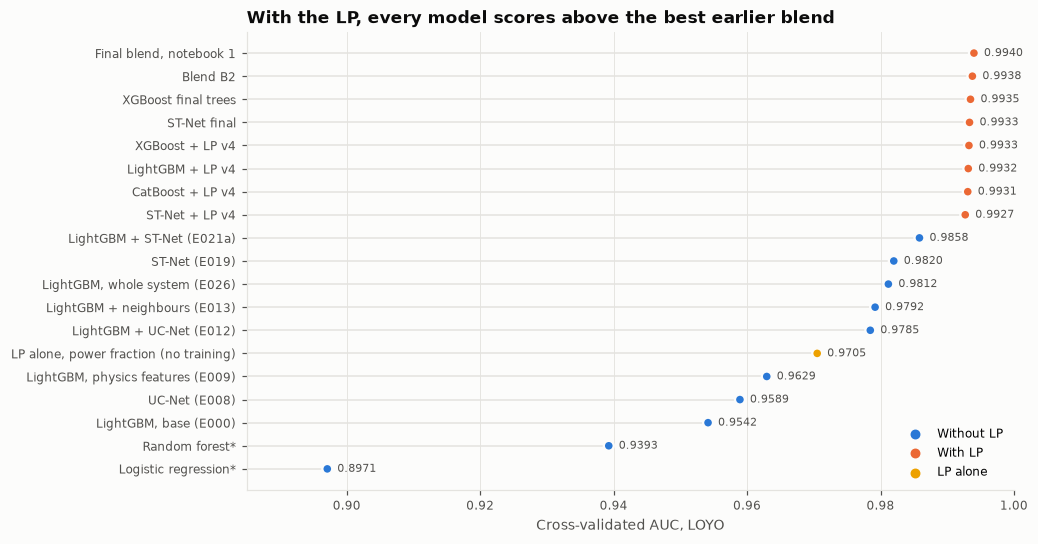

* Three tuning folds only, not all 8 years, so not directly comparable with the others.


In [11]:
pts = [("Logistic regression*", .89708, 0), ("Random forest*", .93927, 0), ("LightGBM, base (E000)", .95415, 0), ("LP alone, power fraction (no training)", auc(Y, LPF[:N_TR]), 2), ("UC-Net (E008)", .95893, 0), ("LightGBM, physics features (E009)", .96295, 0), ("LightGBM + neighbours (E013)", .97919, 0), ("LightGBM, whole system (E026)", .98118, 0), ("ST-Net (E019)", .98199, 0), ("LightGBM + UC-Net (E012)", .97847, 0), ("LightGBM + ST-Net (E021a)", .98584, 0),
    ("LightGBM + LP v4", rows["L8_v4"]["oof_auc"], 1), ("CatBoost + LP v4", rows["C1_v4_mf"]["oof_auc"], 1), ("XGBoost + LP v4", rows["XR_ref"]["oof_auc"], 1), ("ST-Net + LP v4", rows["N4_v4_scale"]["oof_auc"], 1), ("XGBoost final trees", rows["XR_ls"]["oof_auc"], 1), ("ST-Net final", rows["N6_min"]["oof_auc"], 1), ("Blend B2", rows["B2_gbdt3_nn2_nested"]["oof_auc"], 1), ("Final blend, notebook 1", auc(Y, B), 1)]
pts = sorted(pts, key=lambda p: p[1]); cols = [BLUE, ORANGE, YELLOW]; fig, ax = plt.subplots(figsize=(9, 5.4))
ax.hlines(range(len(pts)), .88, [p[1] for p in pts], color=GRID, lw=1); ax.scatter([p[1] for p in pts], range(len(pts)), s=42, c=[cols[p[2]] for p in pts], zorder=3, edgecolors="#fcfcfb", linewidths=1.5); ax.set_yticks(range(len(pts)), [p[0] for p in pts]); ax.set_xlim(.885, 1.0); ax.set_xlabel("Cross-validated AUC, LOYO"); ax.grid(axis="y", visible=False); ax.set_title("With the LP, every model scores above the best earlier blend")
for k, p in enumerate(pts): ax.text(p[1] + .0015, k, f"{p[1]:.4f}", va="center", fontsize=7.5, color=MUTED)
for lab, col in (("Without LP", BLUE), ("With LP", ORANGE), ("LP alone", YELLOW)): ax.scatter([], [], s=30, c=col, label=lab)
ax.legend(loc="lower right"); plt.show(); print("* Three tuning folds only, not all 8 years, so not directly comparable with the others.")

The final blend combines two predictor types: gradient-boosted trees and a neural network.

**Proposed, not run:** (P1) pushing the cheapest training hours below zero with LP labels, and (P2) scaling price and water value together. Noise changes the correct label, rolling cases already act as time shifts, and LP-labelled cases lack the SHOP-minus-LP gap the models learn. P1 also cannot be validated, since validation years barely contain negative hours.

## 7. Final models and hyperparameters

**XGBoost:** 66 features (`base,lp,ls` without the 6 absolute price columns), long-format rows, 3 seeds averaged in logit space.

| Parameter | Value | Origin |
|---|---|---|
| `learning_rate`, rounds | 0.08, 300 | From E000. R13 (0.04, 800) was inside noise |
| `max_leaves`, `grow_policy` | 63, lossguide | From E000. Optuna (E011) gave no gain outside its own folds, so I stopped tuning trees |
| `min_child_weight` | 50 | Rough counterpart to LightGBM's `min_data_in_leaf` of 500. Not tuned |
| `subsample`, `colsample_bytree`, `reg_lambda` | 0.5, 0.8, 1.0 | From E000. Not tuned |
| Seeds | 3 | Seed std is 0.00003 LOYO, 0.00006-0.00009 forward (R1) |

**ST-Net:** 70 features (`base,lp,ls`), one token per (unit, hour). Four blocks combine a dilated convolution over the week (dilation 1, 2, 4, 8, conditioned on a unit summary) with attention across units. One Transformer layer follows. The output enforces the start order from 3.2, and an auxiliary head predicts weekly on-share.

| Parameter | Value | Origin |
|---|---|---|
| Epochs | 24 | Beats e12 on two seed sets, LOYO and forward (R20) |
| `d`, blocks, heads | 64, 4, 4 | Sized for repeated runs. d=96 was worse (R15, 1/4 years) |
| Dropout, weight decay | 0.1, 0.01 | From E019. Single-seed checks of alternatives (+0.00016, +0.0006) stayed below the 3-seed reference (+0.0012, R10) and were not repeated at 3 seeds, so these values are kept, not shown best |
| Learning rate, batch, EMA | 1e-3 with warmup and cosine decay, 32, 0.995 | From E008 and E019 |
| Aux weight | 0.3 | From E008 |
| Seeds | 3 | Seed sets differ by up to 0.00035 alone, but barely in the blend. Six add nothing (R14) |

**LP:** YAML values where specified. Bypass cost swept over 10, 100, 1000 on the LP alone; 10, the documented value, was best. The ±10 % sensitivity scale was set in advance.

**Blend weight:** 0.7 trees, 0.3 net, fixed before the last round. Validation is flat (table below), and nested weights on an earlier model set were 0.65-0.70 in all folds. The weight is not nested for the final pair.

In [12]:
f = lambda a, b, w: w * a + (1 - w) * b; okf = np.isfinite(XF).all((1, 2)); W = [.5, .6, .7, .8, .9, 1.]
display(pd.DataFrame({"Tree weight": W, "LOYO": [auc(Y, f(XT, NT, w)) for w in W], "Forward": [auc(Y[okf], f(XF, NF, w)[okf]) for w in W]}).round(5).set_index("Tree weight").T)
print("Correlation between tree and net logits:", round(np.corrcoef(XT.ravel(), NT.ravel())[0, 1], 3))

Tree weight,0.5,0.6,0.7,0.8,0.9,1.0
LOYO,0.99403,0.99404,0.99400,0.99391,0.99374,0.99349
Forward,0.99374,0.99379,0.99379,0.99373,0.99361,0.99341


Correlation between tree and net logits: 0.97


## 8. Model interpretation

All methods use models trained before 2022 and explained on held-out 2022, seed 0.

### 8.1 SHAP on the trees

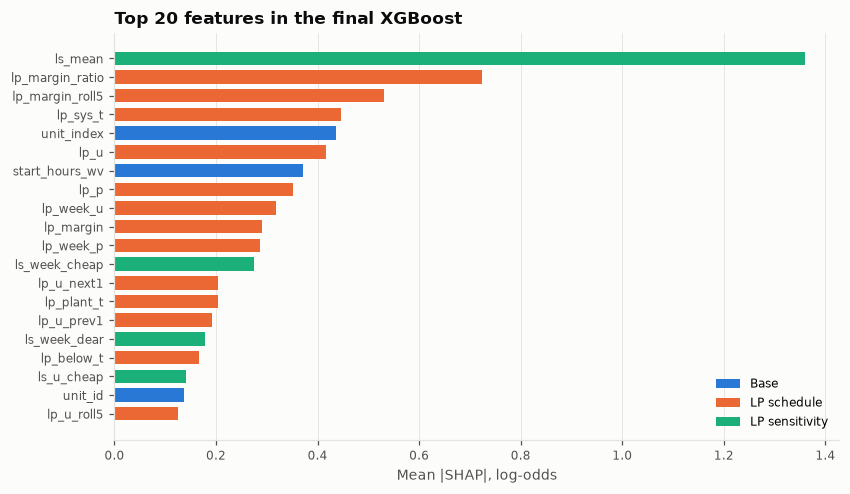

Share of total mean |SHAP| by group: {'base': 0.226, 'lp': 0.554, 'ls': 0.22}
Top 8 by gain: ['lp_u', 'ls_mean', 'lp_u_next1', 'lp_u_prev1', 'lp_u_roll5', 'lp_p', 'lp_week_u', 'lp_week_p']


In [13]:
S = np.load("artifacts/shap_final.npz", allow_pickle=True); sj = json.load(open("artifacts/shap_final.json")); nm = S["names"]; imp = S["imp"]; o = np.argsort(-imp)[:20][::-1]; gc = {"base": BLUE, "lp": ORANGE, "ls": AQUA}
fig, ax = plt.subplots(figsize=(8.5, 4.8)); ax.barh(range(20), imp[o], color=[gc[group(nm[k])] for k in o], height=.72); ax.set_yticks(range(20), nm[o]); ax.set_xlabel("Mean |SHAP|, log-odds"); ax.grid(axis="y", visible=False); ax.set_title("Top 20 features in the final XGBoost")
for lab, gg in (("Base", "base"), ("LP schedule", "lp"), ("LP sensitivity", "ls")): ax.barh([0], [0], color=gc[gg], label=lab)
ax.legend(loc="lower right"); plt.show(); print("Share of total mean |SHAP| by group:", {k: round(v, 3) for k, v in sj["groups"].items()})
g_ = sj["gain"]; print("Top 8 by gain:", sorted(g_, key=g_.get, reverse=True)[:8])

LP features hold 77 % of the attribution.

- `ls_mean` ranks first: a soft LP decision that also reflects how firm the decision is.
- `lp_margin_ratio` and `lp_margin_roll5` compare price with the LP's marginal cost, so the model refines near-ties instead of copying the schedule.
- `lp_sys_t` adds system state. `unit_index` and the other unit columns capture base rates and start order.
- `start_hours_wv` surprised me. I expected high start cost in hours to discourage running, but the next figure shows the opposite. High values occur when water value is near zero, so it seems to mark cheap water.

Gain ranks `lp_u` first, since a few early high-gain splits use it.

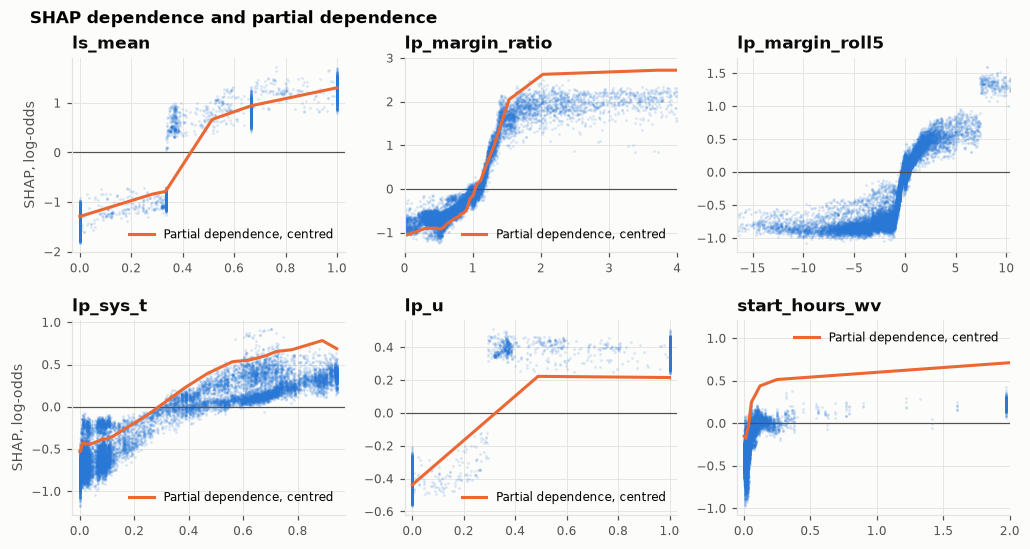

In [14]:
top = [str(x) for x in nm[S["top"]]]; show = ["ls_mean", "lp_margin_ratio", "lp_margin_roll5", "lp_sys_t", "lp_u", "start_hours_wv"]; fig, axs = plt.subplots(2, 3, figsize=(11, 5.4), gridspec_kw=dict(hspace=.35, wspace=.22))
for ax, n in zip(axs.ravel(), show):
    j = top.index(n); x, s = S["x"][:, j], S["sv"][:, j]; hi = np.quantile(x, .995); lo = np.quantile(x, .005); ax.scatter(x, s, s=3, alpha=.18, c=BLUE, linewidths=0); ax.set_xlim(*{"lp_margin_ratio": (0, 4), "start_hours_wv": (-.05, 2)}.get(n, (lo - (hi - lo) * .03, hi + (hi - lo) * .03))); ax.axhline(0, color=MUTED, lw=.8); ax.set_title(n)
    if n in interp["pdp"]:
        q = interp["pdp"][n]; base_ = np.mean(q["y"]); ax.plot(q["x"], np.array(q["y"]) - base_, color=ORANGE, label="Partial dependence, centred")
        ax.legend(loc="best")
axs[0, 0].set_ylabel("SHAP, log-odds"); axs[1, 0].set_ylabel("SHAP, log-odds"); fig.suptitle("SHAP dependence and partial dependence", fontsize=11, fontweight="bold", x=.09, ha="left", y=.96); plt.show()

- `ls_mean` clusters near 0, 1/3, 2/3 and 1. Each step raises the odds, most from 1/3 to 2/3.
- `lp_margin_roll5` and `lp_margin_ratio` rise sharply where price passes the LP's marginal cost (margin 0, ratio 1), then flatten.
- `lp_sys_t` rises with system output. `lp_u` matters mostly between off and partly on.
- Partial dependence (orange, 20 000 rows) agrees with SHAP in direction. Sizes differ, since it sweeps one feature through combinations absent from the data.

### 8.2 Per-unit attribution

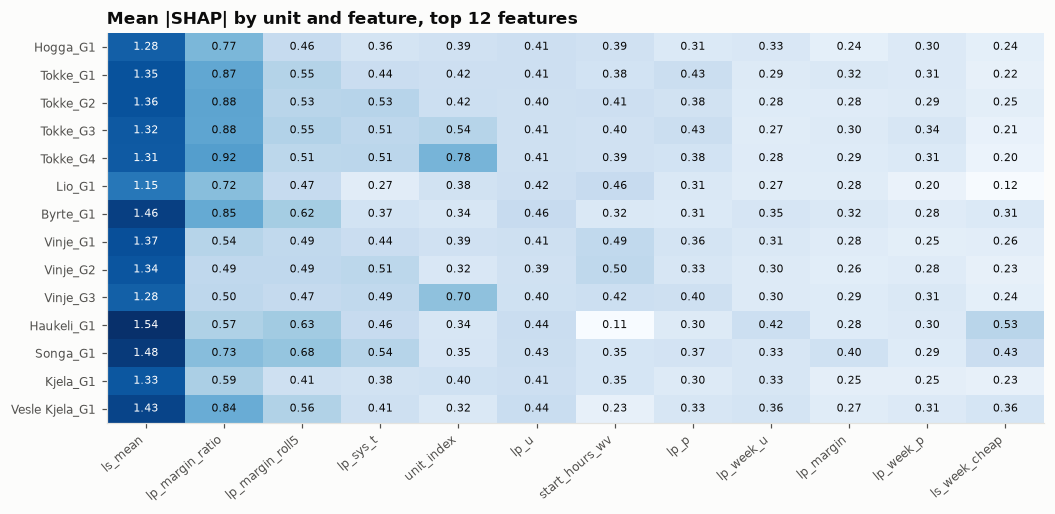

In [15]:
un = S["unit"]; ks = [top.index(n) for n in top[:12]]; M = np.array([[np.abs(S["sv"][un == g_, k]).mean() for k in ks] for g_ in range(14)]); fig, ax = plt.subplots(figsize=(11, 4.6)); heat(ax, M, [top[k] for k in ks], UNITS, "Mean |SHAP| by unit and feature, top 12 features", fmt="{:.2f}"); ax.tick_params(axis="x", rotation=40); plt.setp(ax.get_xticklabels(), ha="right"); plt.show()

`ls_mean` leads for every unit. `unit_index` matters most late in the start order (Tokke G4 0.78, Vinje G3 0.70). `start_hours_wv` barely matters for Haukeli (0.11), which rarely switches.

### 8.3 Permutation importance: trees, net and blend

Each (case, unit) receives its week-long feature track from another random (case, unit). Shuffled inputs are not physically consistent, so the AUC loss is a sensitivity. Groups use 3 shuffles.

Hypothesis, logged before running: both models lean mainly on the LP schedule, and the net loses more than the trees when market columns are shuffled, because it has the absolute columns.

Unshuffled AUC on 2022, seed 0: {'xgb': 0.9924, 'net': 0.99096, 'blend': 0.99268}


,xgb,net,blend,columns
Shuffled group,,,,
lp_schedule,-0.23812,-0.23941,-0.21601,36
lp_sensitivity,-0.01801,-0.02430,-0.01597,7
unit,-0.00416,-0.08165,-0.00329,5
water_state,-0.00184,-0.00325,-0.00150,9
market,-0.00046,-0.00868,-0.00143,10
calendar,-0.00114,-0.00127,-0.00110,5


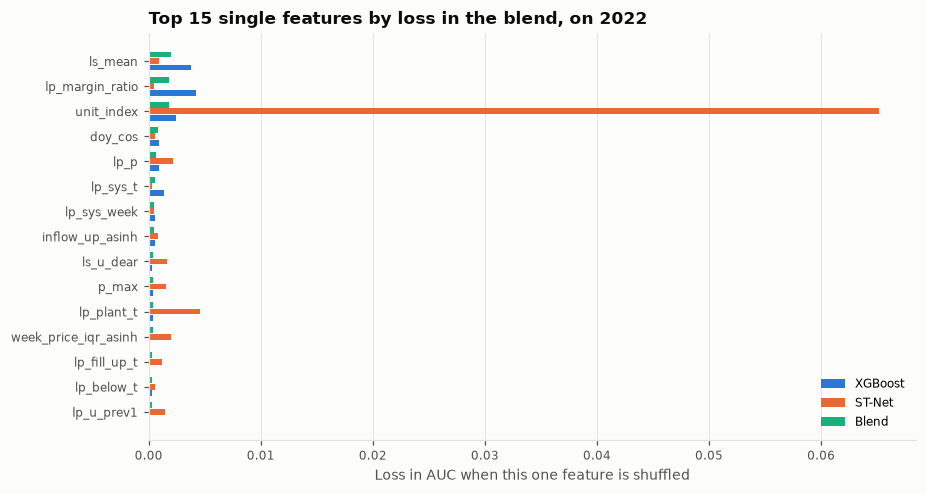

In [16]:
gi = pd.DataFrame(interp["group"]).T[["xgb", "net", "blend"]]; gi["columns"] = [len(G[k]) for k in gi.index]; print("Unshuffled AUC on 2022, seed 0:", {k: round(v, 5) for k, v in interp["base"].items()}); display(gi.sort_values("blend").round(5).rename_axis("Shuffled group"))
si = pd.DataFrame(interp["single"]).T; si = si.sort_values("blend").head(15)[::-1]; fig, ax = plt.subplots(figsize=(9, 4.8)); yy = np.arange(len(si)); w_ = .26
for k, (m_, col) in enumerate((("xgb", BLUE), ("net", ORANGE), ("blend", AQUA))): ax.barh(yy + (k - 1) * w_, -si[m_], height=w_ * .9, color=col, label={"xgb": "XGBoost", "net": "ST-Net", "blend": "Blend"}[m_])
ax.set_yticks(yy, si.index); ax.grid(axis="y", visible=False); ax.set_xlabel("Loss in AUC when this one feature is shuffled"); ax.set_title("Top 15 single features by loss in the blend, on 2022"); ax.legend(loc="lower right"); plt.show()

The hypothesis held. Shuffling the LP schedule costs about 0.24 in both models, far above any other group, followed by LP sensitivity (about 0.02). Market columns cost the net 0.0087 against 0.0005 for the trees. Not predicted: the net loses 0.082 on the unit group and 0.065 on `unit_index` alone, despite having a unit embedding. I do not know why. The blend loses only 0.0018 on that column. Single features cost at most 0.002 in the blend, since LP columns can replace each other, so read the bars together with the group table. They use one shuffle and one seed, and differences below about 0.0002 are not meaningful.

### 8.4 One week, side by side

A case with median blend AUC, unseen in its fold.

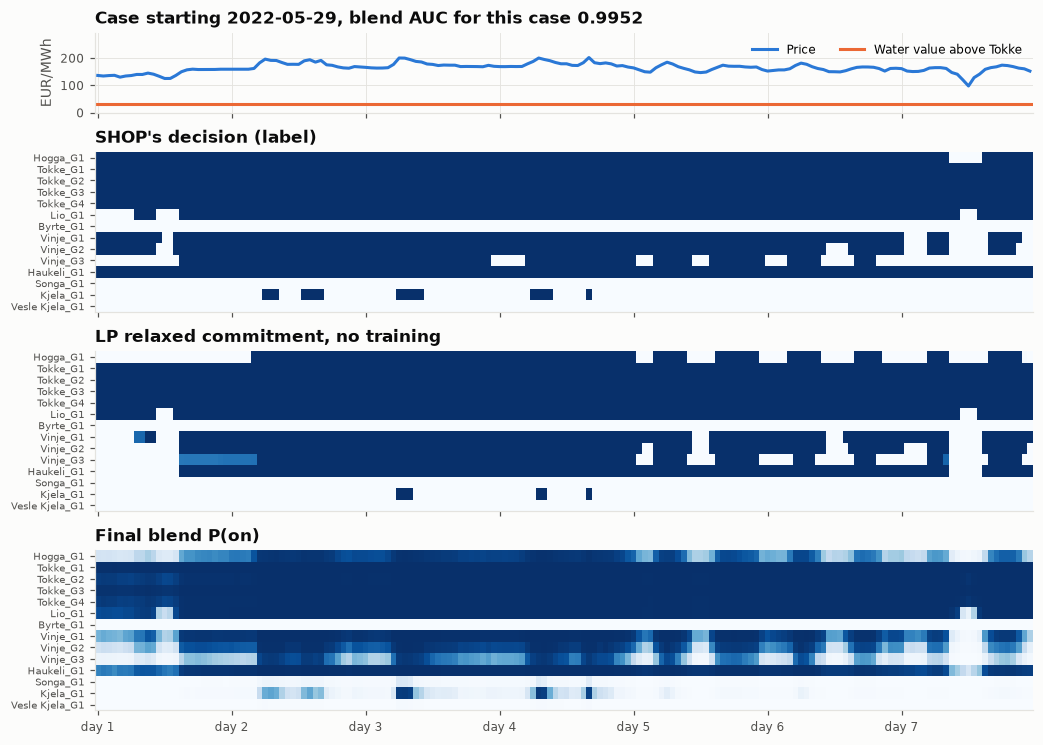

In [17]:
ca = np.array([auc(Y[k].ravel(), B[k].ravel()) if 0 < Y[k].mean() < 1 else np.nan for k in range(N_TR)]); k = int(np.nanargmin(np.abs(ca - np.nanmedian(ca)))); fig, axs = plt.subplots(4, 1, figsize=(11, 8), sharex=True, gridspec_kw=dict(hspace=.28, height_ratios=[1, 2, 2, 2]))
axs[0].plot(P[k], color=BLUE, label="Price"); wvu = wv[k, ri[UP[UNITS.index("Tokke_G1")]]]; axs[0].axhline(wvu, color=ORANGE, label="Water value above Tokke"); axs[0].set_ylabel("EUR/MWh"); axs[0].set_ylim(0, P[k].max() * 1.45); axs[0].legend(loc="upper right", ncol=2); axs[0].set_title(f"Case starting {c['start'][k]}, blend AUC for this case {ca[k]:.4f}")
for ax, M, tt in ((axs[1], Y[k], "SHOP's decision (label)"), (axs[2], LPU[k], "LP relaxed commitment, no training"), (axs[3], 1 / (1 + np.exp(-B[k])), "Final blend P(on)")):
    ax.imshow(M, aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="nearest"); ax.grid(False); ax.set_yticks(range(14), UNITS, fontsize=6.5); ax.set_title(tt)
axs[3].set_xticks(range(0, 168, 24), [f"day {d + 1}" for d in range(7)]); plt.show()

The LP gets most of the plan without training: Tokke, Lio and Byrte are almost exact. It wrongly holds Hogga, Vinje and Haukeli off for the first day or more, and switches Haukeli off late in day 7. The blend moves toward SHOP there and partly picks up the short Kjela runs. It also inherits LP errors: in days 5-7 it follows the LP's on/off pattern for Hogga, where SHOP stays on.

## 9. Error analysis

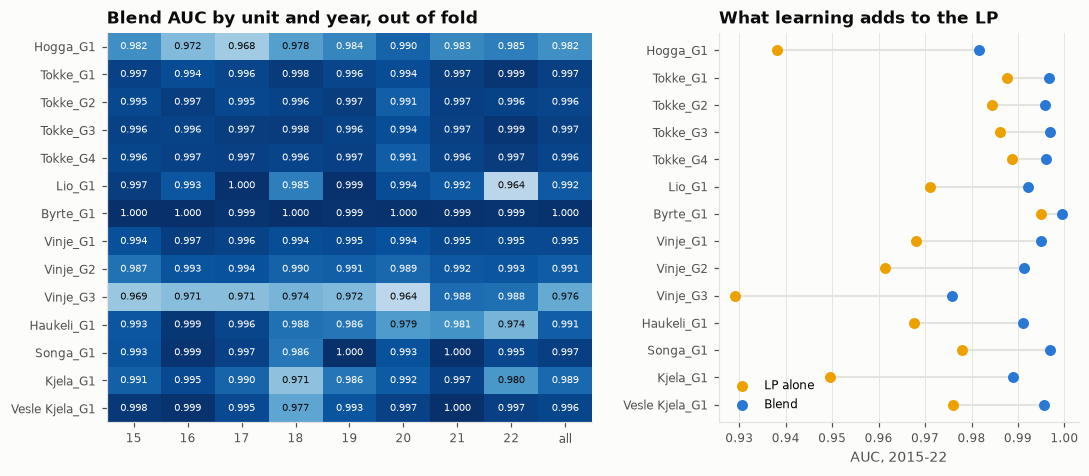

,Vinje_G3,Hogga_G1,Kjela_G1,Haukeli_G1,Vinje_G2,Lio_G1,Vinje_G1,Vesle Kjela_G1,Tokke_G2,Tokke_G4,Tokke_G1,Tokke_G3,Songa_G1,Byrte_G1
LP alone,0.9291,0.9382,0.9495,0.9676,0.9614,0.9710,0.9680,0.9760,0.9844,0.9888,0.9876,0.9861,0.9780,0.9950
XGBoost,0.9742,0.9805,0.9871,0.9905,0.9905,0.9913,0.9945,0.9954,0.9952,0.9956,0.9965,0.9965,0.9965,0.9995
ST-Net,0.9738,0.9804,0.9886,0.9895,0.9913,0.9906,0.9948,0.9950,0.9957,0.9958,0.9965,0.9969,0.9967,0.9994
Blend,0.9758,0.9816,0.9889,0.9911,0.9914,0.9922,0.9950,0.9956,0.9958,0.9960,0.9968,0.9969,0.9969,0.9995


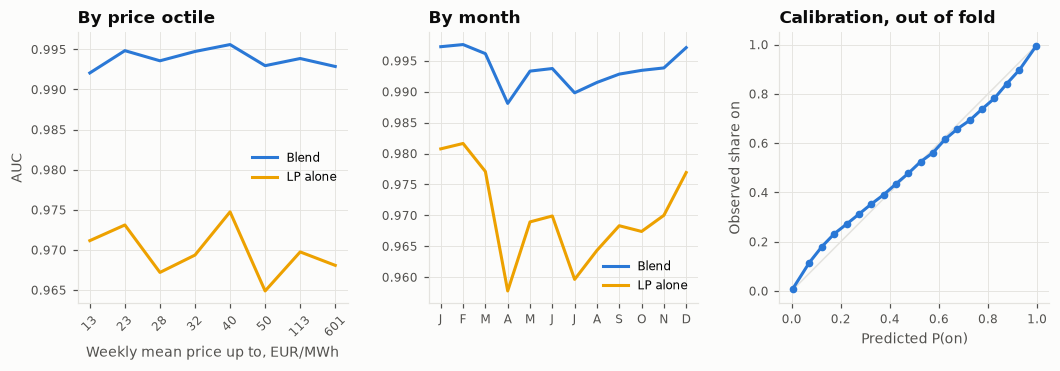

Blend AUC per year: {2015: 0.99443, 2016: 0.99556, 2017: 0.99476, 2018: 0.99037, 2019: 0.99468, 2020: 0.99214, 2021: 0.99547, 2022: 0.99284}


AUC if only the weekly level were known, true level: 0.9809 | blend's level: 0.973


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11.4, 4.6), gridspec_kw=dict(wspace=.3, width_ratios=[1.35, 1])); M = np.array([[auc(Y[ytr == y, g_], B[ytr == y, g_]) for y in YRS] + [auc(Y[:, g_], B[:, g_])] for g_ in range(14)]); heat(ax[0], M, [str(y)[2:] for y in YRS] + ["all"], UNITS, "Blend AUC by unit and year, out of fold", .95, 1., "{:.3f}", cmap="Blues", size=6.5)
L = [auc(Y[:, g_], LPF[:N_TR, g_]) for g_ in range(14)]; Bl = [auc(Y[:, g_], B[:, g_]) for g_ in range(14)]; X_ = [auc(Y[:, g_], XT[:, g_]) for g_ in range(14)]; N_ = [auc(Y[:, g_], NT[:, g_]) for g_ in range(14)]; yy = np.arange(14)
ax[1].hlines(yy, L, Bl, color=GRID, lw=1.4); ax[1].scatter(L, yy, s=38, c=YELLOW, label="LP alone", zorder=3); ax[1].scatter(Bl, yy, s=38, c=BLUE, label="Blend", zorder=3); ax[1].set_yticks(yy, UNITS); ax[1].invert_yaxis(); ax[1].grid(axis="y", visible=False); ax[1].legend(loc="lower left"); ax[1].set_title("What learning adds to the LP"); ax[1].set_xlabel("AUC, 2015-22"); plt.show()
display(pd.DataFrame({"LP alone": L, "XGBoost": X_, "ST-Net": N_, "Blend": Bl}, index=UNITS).round(4).sort_values("Blend").T)
wm = P[:N_TR].mean(1); bins = np.quantile(wm, np.linspace(0, 1, 9)); pb = np.digitize(wm, bins[1:-1]); mo = starts[:N_TR].month.values; ex = lambda a, m: auc(Y[m], a[m])
fig, ax = plt.subplots(1, 3, figsize=(11.4, 3.2), gridspec_kw=dict(wspace=.3))
ax[0].plot(range(8), [ex(B, pb == k) for k in range(8)], color=BLUE, label="Blend"); ax[0].plot(range(8), [ex(LPF[:N_TR], pb == k) for k in range(8)], color=YELLOW, label="LP alone"); ax[0].set_xticks(range(8), [f"{bins[k + 1]:.0f}" for k in range(8)], rotation=45); ax[0].set_xlabel("Weekly mean price up to, EUR/MWh"); ax[0].set_ylabel("AUC"); ax[0].set_title("By price octile"); ax[0].legend()
ax[1].plot(range(1, 13), [ex(B, mo == m) for m in range(1, 13)], color=BLUE, label="Blend"); ax[1].plot(range(1, 13), [ex(LPF[:N_TR], mo == m) for m in range(1, 13)], color=YELLOW, label="LP alone"); ax[1].set_xticks(range(1, 13), ml); ax[1].set_title("By month"); ax[1].legend()
pb_ = 1 / (1 + np.exp(-B)); bn = np.linspace(0, 1, 21); ix = np.digitize(pb_.ravel(), bn) - 1; mp = [pb_.ravel()[ix == k].mean() for k in range(20)]; my = [Y.ravel()[ix == k].mean() for k in range(20)]; ax[2].plot([0, 1], [0, 1], color=GRID, lw=1); ax[2].plot(mp, my, color=BLUE, marker="o", ms=4); ax[2].set_xlabel("Predicted P(on)"); ax[2].set_ylabel("Observed share on"); ax[2].set_title("Calibration, out of fold"); plt.show()
print("Blend AUC per year:", {y: round(auc(Y[ytr == y], B[ytr == y]), 5) for y in YRS}); lv = lambda A: np.broadcast_to(A.mean(2, keepdims=True), A.shape); print("AUC if only the weekly level were known, true level:", round(auc(Y, lv(Y)), 4), "| blend's level:", round(auc(Y, lv(B)), 4))

- **Units:** learning adds most where the LP is weakest: Vinje G3 0.929 to 0.976, Hogga 0.938 to 0.982, Kjela 0.950 to 0.989. These remain the weakest. Byrte (0.9995) and Tokke (about 0.996) are nearly solved. The blend matches or beats both members on all 14 units, though their logits correlate at 0.97.
- **Unit and year:** weakest cells are Lio 2022 (0.964), Vinje G3 2020 (0.964), Hogga 2017 (0.968) and Haukeli 2022 (0.974). The weakest year is 2018 (0.99037). 2020, by far the weakest in phase 1 (E021a 0.97653), is now 0.99214.
- **Price and month:** nearly flat across price octiles (0.992-0.996). April is weakest for both blend and LP (0.988, 0.958), then July. I did not investigate why.
- **Level:** the true weekly on-share alone gives 0.981, and the blend's weekly level alone 0.973, so the level still has room.
- **Calibration:** close to the diagonal, slightly overconfident at low probabilities (predicted 0.05, observed about 0.11). The metric uses only ranks, so I did not recalibrate.

## 10. Robustness
### 10.1 Regime holdouts

XGBoost trained on one regime and tested on another. The test sets overlap years available when the LP was designed.

,n train,n val,No LP,LP with prices,"LP, no prices",LP alone (no training)
holdout,,,,,,
train_2015_18_test_2019_22,1461,1461,0.92693,0.99313,0.99281,0.97228
train_2015_19_test_2021_22,1826,730,0.92259,0.99343,0.99330,0.97257
train_2015_20_test_2022,2192,365,0.93113,0.99206,0.99190,0.96757
train_price_low_test_high,2057,742,0.93216,0.99159,0.99176,0.96912
train_price_high_test_low,612,2180,0.90986,0.98995,0.98960,0.97042
train_no_2020_like_test_2020,2424,366,0.92581,0.99069,0.98987,0.97197


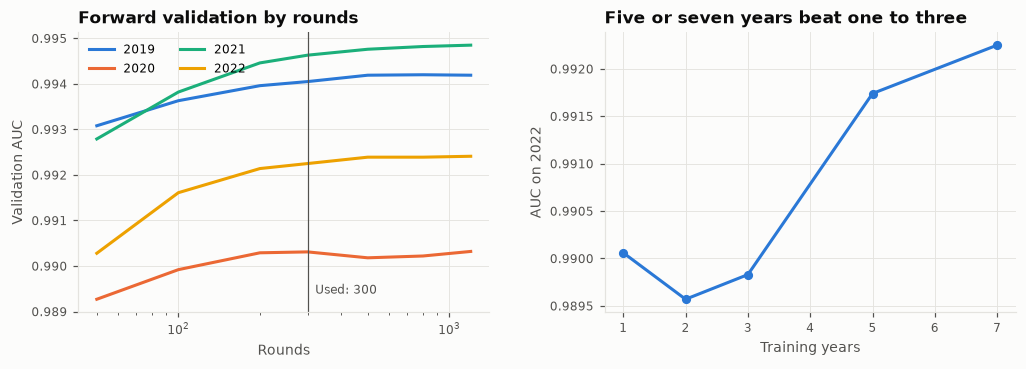

In [19]:
rr = pd.read_csv("artifacts/robust_regime.csv").set_index("holdout"); rr.columns = ["n train", "n val", "No LP", "LP with prices", "LP, no prices", "LP alone (no training)"]; display(rr)
rc = json.load(open("artifacts/robust_curves.json")); fig, ax = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw=dict(wspace=.28)); rs = ["50", "100", "200", "300", "500", "800", "1200"]
for (y, d), col in zip(rc["rounds"].items(), (BLUE, ORANGE, AQUA, YELLOW)): ax[0].plot([int(r) for r in rs], [d[r][1] for r in rs], color=col, label=f"{y}")
ax[0].axvline(300, color=MUTED, lw=.8); ax[0].text(320, ax[0].get_ylim()[0] + .0004, "Used: 300", fontsize=8, color=MUTED); ax[0].set_xscale("log"); ax[0].set_xlabel("Rounds"); ax[0].set_ylabel("Validation AUC"); ax[0].set_title("Forward validation by rounds"); ax[0].legend(ncol=2)
sz = rc["size"]; ax[1].plot([int(k) for k in sz], list(sz.values()), color=BLUE, marker="o", ms=5); ax[1].set_xlabel("Training years"); ax[1].set_ylabel("AUC on 2022"); ax[1].set_title("Five or seven years beat one to three"); plt.show()

- Holdouts score 0.91-0.93 without LP features and about 0.99 with them, a larger gap than any model choice in Section 6.
- Validation never falls with rounds. It gains about 0.0002 from 300 to 1200, and R13 found more rounds inside noise.
- Five or seven training years beat one to three (0.9917, 0.9923, about 0.990), so the final models train on all 8.

### 10.2 Stress tests

Trained before 2022, tested on half of 2022's cases. Inputs are perturbed and **the LP is re-solved**. Labels stay fixed, so these are sensitivities, not scores: SHOP's true decision may change.

In [20]:
sf, sn = json.load(open("artifacts/stress_final.json")), json.load(open("artifacts/stress_noabs.json")); kk = ["scale_0.5", "scale_2", "scale_4", "price_noise", "negative_cheapest"]
display(pd.DataFrame({"XGBoost": [sf[k]["xgb"] for k in kk], "ST-Net, notebook 1": [sf[k]["net"] for k in kk], "ST-Net, notebook 2": [sn[k]["net"] for k in kk], "Blend, notebook 1": [sf[k]["blend"] for k in kk], "Blend, notebook 2": [sn[k]["blend"] for k in kk], "LP schedule changed": [sf[k]["lp_u_change"] for k in kk]}, index=["Price & water value x0.5", "Price & water value x2", "Price & water value x4", "Noise on price", "Cheapest 10 % of hours pushed below zero"]).round(5))
print("Unperturbed blend on this half of 2022: notebook 1", round(sf["base"]["blend"], 5), "| notebook 2", round(sn["base"]["blend"], 5))
print("Mean P(on) in the hours pushed negative: before", round(sf["negative_cheapest"]["p_on_before"], 3), "after", round(sf["negative_cheapest"]["p_on_after"], 3), "| LP:", round(sf["negative_cheapest"]["lp_on_before"], 3), "to", round(sf["negative_cheapest"]["lp_on_after"], 3))
s1 = pd.read_csv("artifacts/submission_1.csv"); T1 = s1.iloc[:, 1:].values.reshape(725, 14, 168); P2 = P[N_TR:]; neg = np.broadcast_to(P2[:, None] < 0, T1.shape); print("\nOn the actual test set (no labels). Mean P(on) in negative-price hours:", round(T1[neg].mean(), 3), "| all other hours:", round(T1[~neg].mean(), 3), "| LP power fraction in negative hours:", round(LPF[N_TR:][neg].mean(), 3))

,XGBoost,"ST-Net, notebook 1","ST-Net, notebook 2","Blend, notebook 1","Blend, notebook 2",LP schedule changed
Price & water value x0.5,-0.00019,0.00011,-0.00032,-0.00007,-0.00022,0.00815
Price & water value x2,0.00072,-0.00032,0.00121,0.00052,0.00085,0.00732
Price & water value x4,-0.00224,-0.00400,-0.00095,-0.00231,-0.00177,0.01414
Noise on price,-0.00816,-0.00743,-0.00668,-0.00754,-0.00759,0.04537
Cheapest 10 % of hours pushed below zero,-0.00792,-0.00618,-0.00459,-0.00722,-0.00668,0.01623


Unperturbed blend on this half of 2022: notebook 1 0.99254 | notebook 2 0.99234
Mean P(on) in the hours pushed negative: before 0.137 after 0.008 | LP: 0.137 to 0.005



On the actual test set (no labels). Mean P(on) in negative-price hours: 0.141 | all other hours: 0.48 | LP power fraction in negative hours: 0.078


- **Scaling** barely moves the result, since the LP schedule hardly changes.
- **Negative prices** are the largest unknown. The blend falls 0.0072. E021a fell 0.0229 under the same perturbation on different validation data, so the comparison is indicative. P(on) drops from 0.14 to 0.01. On the real test set, mean P(on) is 0.14 in negative hours and 0.48 elsewhere. The direction is reasonable, but SHOP's strength of reaction cannot be verified.
- **Price noise** costs 0.0075 but is the least relevant test, since SHOP and the features see the same price.

**Hedge in notebook 2.** Notebook 1 assumes absolute price levels help the net (R6, R21). Notebook 2 removes them. The blend then loses less at x4 scaling (-0.00177 against -0.00231) and on negative prices (-0.00668 against -0.00722), at almost no validation cost (LOYO -0.00001, forward 0.00000). Both share the LP, so this does not protect against LP failure. I rejected LP-free E026 as that hedge: LOYO is about 0.012 lower, and its predecessor E013 fell 0.029 on negative prices (indicative).

Public scores of 0.99638 and 0.99635 agree with validation.

## 11. Reproducibility

Both notebooks contain all code, start from raw data, run offline and use no external data. LP solutions are stored in `work/`, so a run can resume. XGBoost and ST-Net each fall back to the CPU if the GPU fails.

UTKAST: tallene fra de nye kjøringene kommer her.

GPU training is not bit-exact, which explains the small net differences.

**12 hours, 4 CPU cores, 32 GB.** Tested on notebook 1 without a GPU, from an empty directory, with the memory limit enforced by Slurm: 171 minutes in total (ST-Net 128, LP 37, XGBoost 6), peak 18.5 GB (Slurm MaxRSS). The result differs from the GPU run: Spearman 0.99908, largest logit difference 1.26. Notebook 2 uses the same code but was not run this way.

**GPU.** UTKAST: P100-testen kjører.

Versions are in `requirements.txt`: Python 3.12, PyTorch 2.6.0 with CUDA 12.4, XGBoost 3.4.1, SciPy 1.18.1 with HiGHS.

## 12. Limitations

- **No untouched holdout.** The LP structure was chosen by scoring against labels from all training years, so LOYO and forward are somewhat optimistic for LP models. The public leaderboard is the only independent check, and it was consulted several times.
- **Negative prices** are 2.2 % of test hours (1.99 % in 2023, 2.35 % in 2024) and nearly absent from training. The public/private split is unknown, so the private score may react differently.
- **Weakest units:** Vinje G3, Hogga, Kjela. Start costs and integer decisions at small margins are a likely cause, but I did not establish this.
- **LP simplifications:** fixed head within a week, concave efficiency, relaxed commitment. The models correct only what training regimes show.
- **Blend weight:** not nested for the final pair.
- **Interpretation:** SHAP covers only the trees, shuffling breaks physical consistency, and correlated features share credit.
- **Runtime:** the CPU test ran on a server CPU (Xeon Gold 6348, 2.6 GHz), and a laptop can be slower. The margin to 12 hours is a factor of 4.2.

**Tools:** Claude Code (an AI coding assistant) was used for code, analyses and drafting this report. Numbers come from logged runs.